In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import os
os.chdir("/Users/lleid/Downloads")
data = pd.read_csv("recursos_humanos (1).csv")

In [2]:
data

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,support,low
14995,0.37,0.48,2,160,3,0,1,0,support,low
14996,0.37,0.53,2,143,3,0,1,0,support,low
14997,0.11,0.96,6,280,4,0,1,0,support,low


In [3]:
# Revisión de la base
print(data.shape)            
print(data.head())           
print(data.dtypes)          
print(data.isnull().sum())   

(14999, 10)
   satisfaction_level  last_evaluation  number_project  average_montly_hours  \
0                0.38             0.53               2                   157   
1                0.80             0.86               5                   262   
2                0.11             0.88               7                   272   
3                0.72             0.87               5                   223   
4                0.37             0.52               2                   159   

   time_spend_company  Work_accident  left  promotion_last_5years  sales  \
0                   3              0     1                      0  sales   
1                   6              0     1                      0  sales   
2                   4              0     1                      0  sales   
3                   5              0     1                      0  sales   
4                   3              0     1                      0  sales   

   salary  
0     low  
1  medium  
2  medium  
3 

In [4]:
# 1) Recodificar las variables de texto con get_dummies
data_dummies = pd.get_dummies(data, columns=["sales", "salary"], drop_first=True, dtype=int)
print(data_dummies.head())
print(data_dummies.columns.tolist())   # para ver las columnas nuevas

   satisfaction_level  last_evaluation  number_project  average_montly_hours  \
0                0.38             0.53               2                   157   
1                0.80             0.86               5                   262   
2                0.11             0.88               7                   272   
3                0.72             0.87               5                   223   
4                0.37             0.52               2                   159   

   time_spend_company  Work_accident  left  promotion_last_5years  \
0                   3              0     1                      0   
1                   6              0     1                      0   
2                   4              0     1                      0   
3                   5              0     1                      0   
4                   3              0     1                      0   

   sales_RandD  sales_accounting  sales_hr  sales_management  sales_marketing  \
0            0         

In [5]:
print(data["left"].value_counts())                           
print((data["left"].value_counts(normalize=True) * 100).round(1))  

left
0    11428
1     3571
Name: count, dtype: int64
left
0    76.2
1    23.8
Name: proportion, dtype: float64


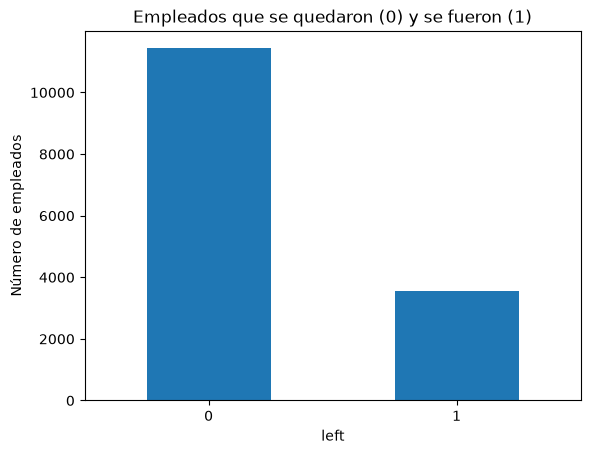

In [6]:
# Gráfica de barras
data["left"].value_counts().plot(kind="bar")
plt.title("Empleados que se quedaron (0) y se fueron (1)")
plt.ylabel("Número de empleados")
plt.xticks(rotation=0)  
plt.show()

In [7]:
# También las otras categóricas de texto
for col in ["sales", "salary"]:
    print("\n", col)
    print(data[col].value_counts())


 sales
sales
sales          4140
technical      2720
support        2229
IT             1227
product_mng     902
marketing       858
RandD           787
accounting      767
hr              739
management      630
Name: count, dtype: int64

 salary
salary
low       7316
medium    6446
high      1237
Name: count, dtype: int64


In [8]:
y = data_dummies.left.values
x_data_dummies = data_dummies.drop(["left"], axis = 1)

In [9]:
y

array([1, 1, 1, ..., 1, 1, 1], shape=(14999,))

In [10]:
x_data_dummies

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,0,0,0,0,0,0,0,1,0,0,1,0
1,0.80,0.86,5,262,6,0,0,0,0,0,0,0,0,1,0,0,0,1
2,0.11,0.88,7,272,4,0,0,0,0,0,0,0,0,1,0,0,0,1
3,0.72,0.87,5,223,5,0,0,0,0,0,0,0,0,1,0,0,1,0
4,0.37,0.52,2,159,3,0,0,0,0,0,0,0,0,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,0,0,0,0,0,0,0,0,1,0,1,0
14995,0.37,0.48,2,160,3,0,0,0,0,0,0,0,0,0,1,0,1,0
14996,0.37,0.53,2,143,3,0,0,0,0,0,0,0,0,0,1,0,1,0
14997,0.11,0.96,6,280,4,0,0,0,0,0,0,0,0,0,1,0,1,0


In [11]:
#Normañlizacion
x = (x_data_dummies - x_data_dummies.min()) / (x_data_dummies.max() - x_data_dummies.min())

print(x.max())  
print(x.min()) 

satisfaction_level       1.0
last_evaluation          1.0
number_project           1.0
average_montly_hours     1.0
time_spend_company       1.0
Work_accident            1.0
promotion_last_5years    1.0
sales_RandD              1.0
sales_accounting         1.0
sales_hr                 1.0
sales_management         1.0
sales_marketing          1.0
sales_product_mng        1.0
sales_sales              1.0
sales_support            1.0
sales_technical          1.0
salary_low               1.0
salary_medium            1.0
dtype: float64
satisfaction_level       0.0
last_evaluation          0.0
number_project           0.0
average_montly_hours     0.0
time_spend_company       0.0
Work_accident            0.0
promotion_last_5years    0.0
sales_RandD              0.0
sales_accounting         0.0
sales_hr                 0.0
sales_management         0.0
sales_marketing          0.0
sales_product_mng        0.0
sales_sales              0.0
sales_support            0.0
sales_technical          0.0

In [12]:
x

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_low,salary_medium
0,0.318681,0.265625,0.0,0.285047,0.125,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,0.780220,0.781250,0.6,0.775701,0.500,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2,0.021978,0.812500,1.0,0.822430,0.250,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,0.692308,0.796875,0.6,0.593458,0.375,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,0.307692,0.250000,0.0,0.294393,0.125,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14994,0.340659,0.328125,0.0,0.257009,0.125,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
14995,0.307692,0.187500,0.0,0.299065,0.125,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
14996,0.307692,0.265625,0.0,0.219626,0.125,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
14997,0.021978,0.937500,0.8,0.859813,0.250,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


In [13]:
#Bases de entrenamiento y prueba 
from sklearn.model_selection import train_test_split 
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size = 0.30, random_state = 1)

In [15]:
#Modelo KNN (K vecinos mas cercanos)
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors = 2)
knn.fit(x_train, y_train)
prediction = knn.predict(x_test)
print("Score: ", knn.score(x_test, y_test))
#el score con k=2 fue de 0.957

Score:  0.9577777777777777


In [16]:
y_pred = prediction
y_true = y_test

In [17]:
#Creacion de la matriz de confusion
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true, y_pred)
cm

array([[3333,   83],
       [ 107,  977]])

<function matplotlib.pyplot.show(close=None, block=None)>

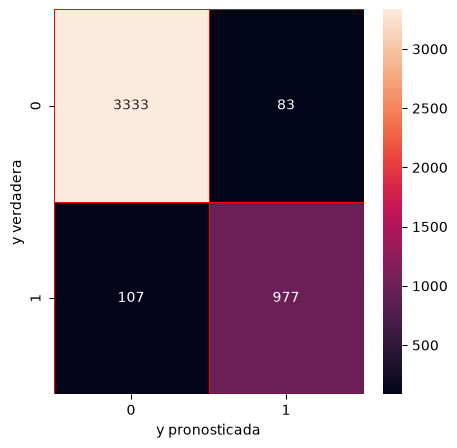

In [18]:
#Visualizacion de la matriz de confusion
import seaborn as sns 
f, ax = plt.subplots(figsize = (5,5))

sns.heatmap(cm, annot = True, linewidths = 0.5, linecolor = "red", fmt = ".0f", ax = ax)
plt.xlabel("y pronosticada")
plt.ylabel("y verdadera")
plt.show

In [19]:
#Calculo de la precision global 
Correctos = cm[0,0] + cm [1,1]
Incorrecto = cm[0,1] + cm [1,0]
PrecisionGlobal = Correctos / (Correctos + Incorrecto)
PrecisionGlobal

np.float64(0.9577777777777777)

In [21]:
PrecisionF = cm[0,0] / (cm[0,0] + cm [1,0])  #Q es que que quedo o que no se fue y F es que se fue
PrecisionF

np.float64(0.9688953488372093)

In [22]:
PrecisionQ = cm[1,1] / (cm[1,1] + cm[0,1])
PrecisionQ 

np.float64(0.9216981132075471)

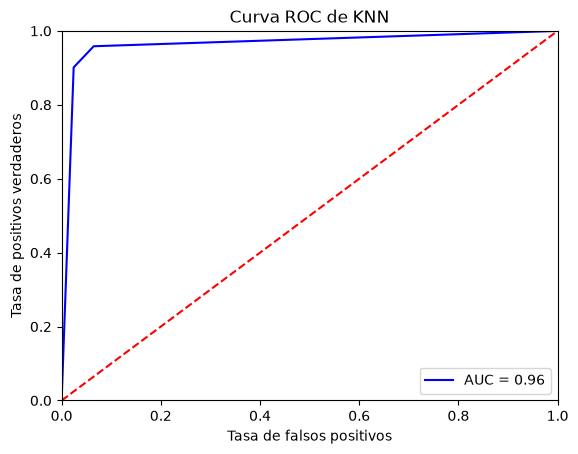

In [23]:
from sklearn.metrics import roc_curve
from sklearn.metrics import auc

y_scores = knn.predict_proba(x_test)

fpr, tpr, threshold = roc_curve(y_test, y_scores[:,1])
#fpr = false positive rate, tpr= true positive rate
roc_auc = auc(fpr, tpr)
plt.title('Receiver Operating Characteristic')
plt.plot(fpr, tpr,'b', label = 'AUC = %0.2f'% roc_auc)
plt.legend(loc = "lower right")
plt.plot([0,1],[0,1],'r--')
plt.xlim([0,1])
plt.ylim([0,1])
plt.ylabel("Tasa de positivos verdaderos")
plt.xlabel("Tasa de falsos positivos")
plt.title("Curva ROC de KNN")
plt.show()